## Homework 4

## Data cleaning

* Columns normalization to lower case and replacing spaces with underscores
* Text normalization for categorical columns
* Nulls validation: replace null values for categorical variables with NA and 0 for numeric variables

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)

for column in categorical_columns:
    df[column] = df[column].str.lower().str.replace(' ', '_')
    df[column] = df[column].fillna("NA")

for column in numerical_columns:
    df[column] = df[column].fillna(0.0)

## Validation Framework

In [2]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train.converted.values

## AUC for numerical variables

In [12]:
from sklearn.metrics import auc, roc_auc_score

numerical = ['annual_income','lead_score', 'number_of_courses_viewed', 'interaction_count']
scores = {}

for feature in numerical:
    
    score = roc_auc_score(y_train, df_train[feature])

    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])

    scores[feature] = score

print(scores)

{'annual_income': 0.6081977776250831, 'lead_score': 0.7882254810906102, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227}


## Logistic regression

In [21]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income','lead_score', 'number_of_courses_viewed', 'interaction_count']

In [22]:
def logistic_training(df_to_train, y_to_train, regularization=1.0):
    dv = DictVectorizer(sparse=False)
    train_dict = df_to_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(solver='liblinear', C=regularization, max_iter=1000)
    model.fit(X_train, y_to_train)
    
    return dv, model

In [29]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [30]:
dv, model = logistic_training(df_train, y_train)

In [31]:
y_predict = predict(df_val, dv, model)

In [33]:
t1_score = roc_auc_score(y_val, y_predict)
round(t1_score, 3)

0.732

## Precision and Recall

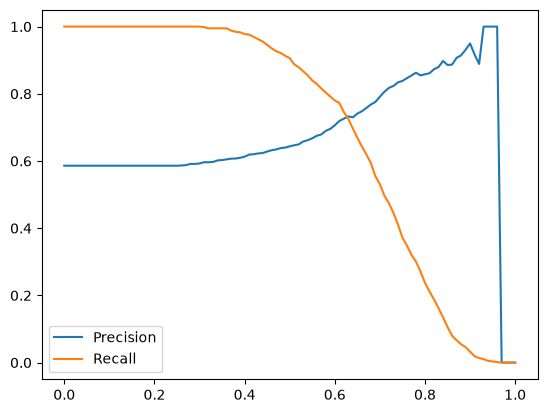

In [39]:
import matplotlib.pyplot as plt

thresholds = np.arange(0, 1.01, 0.01)

scores = []

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

for t in thresholds:
    predict_positive = (y_predict >= t)
    predict_negative = (y_predict < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append((t, p, r))

columns = ['threshold', 'precision', 'recall']
df_pr = pd.DataFrame(scores, columns = columns)

plt.plot(df_pr.threshold, df_pr['precision'], label='Precision')
plt.plot(df_pr.threshold, df_pr['recall'], label='Recall')
plt.legend()

In [41]:
df_pr['diff'] = abs(df_pr.precision - df_pr.recall)

df_filtered = df_pr[(df_pr.precision != 0) | (df_pr.recall != 0)]

df_filtered.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


## F1 Score

In [44]:
df_pr['f1'] = (2*((df_pr.precision * df_pr.recall)/(df_pr.precision + df_pr.recall))).fillna(0)
df_pr.sort_values('f1', ascending=False).head()

    

,threshold,precision,recall,diff,f1
41,0.41,0.619048,0.976109,0.357062,0.757616
42,0.42,0.620087,0.969283,0.349196,0.756325
43,0.43,0.622517,0.962457,0.339941,0.756032
45,0.45,0.628118,0.945392,0.317275,0.754768
44,0.44,0.623608,0.955631,0.332023,0.754717


## Fold CV

In [49]:
from sklearn.model_selection import KFold

In [64]:
def kflod_eva(splits, regularizations=[1.0]):
    for regularization in regularizations:
        kflod = KFold(n_splits=splits, shuffle=True, random_state=1)
        scores = []

        for train_idx, val_idx in kflod.split(df_full_train):
            df_to_train = df_full_train.iloc[train_idx]
            df_to_val = df_full_train.iloc[val_idx]

            y_to_train = df_to_train.converted.values
            y_to_val = df_to_val.converted.values

            dv, model = logistic_training(df_to_train, y_to_train, regularization=regularization)
            y_pred = predict(df_to_val, dv, model)

            auc = roc_auc_score(y_to_val, y_pred)
            scores.append(auc)

        print('C=%s %.3f +- %.3f' % (regularization, np.mean(scores), np.std(scores)))

In [65]:
kflod_eva(splits=5)

C=1.0 0.732 +- 0.007


In [66]:
kflod_eva(splits=5,regularizations=[0.000001, 0.001, 1])

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
